In [1]:
import pandas as pd
import numpy as np
import sqlite3
import os
import matplotlib.pyplot as plt

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

conn = sqlite3.connect(r"C:\Users\ADMIN\smart agricultural analytics\agriculture.db")
df = pd.read_sql("SELECT * FROM agri_yield_train_selected", conn)
conn.close()

os.makedirs("stage21_outputs", exist_ok=True)

print(df.shape)

(10000, 11)


In [2]:
features = [
    "NDVI_Temperature", "OrganicMatter_Sand",
    "Temperature_Rainfall", "sand_pct", "NDVI_Rainfall",
    "soil_ph", "organic_matter", "Humidity_Rainfall",
    "Temperature_Humidity", "rainfall"
]

X = df[features]
y = df["yield"]

print(X.shape, y.shape)

(10000, 10) (10000,)


In [3]:
models = {
    "Dummy": DummyRegressor(),
    "Random Forest": RandomForestRegressor(
        n_estimators=200, max_depth=10,
        min_samples_leaf=5, random_state=42
    ),
    "Gradient Boosting": GradientBoostingRegressor(
        n_estimators=100, max_depth=2,
        learning_rate=0.03, random_state=42
    )
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = {}
rows = []

for name, model in models.items():
    pipe = make_pipeline(SimpleImputer(strategy="median"), model)
    pred = cross_val_predict(pipe, X, y, cv=cv)
    results[name] = pred

    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y, pred),
        "RMSE": np.sqrt(mean_squared_error(y, pred)),
        "R2": r2_score(y, pred)
    })

metrics = pd.DataFrame(rows)
metrics.to_csv("stage21_outputs/model_comparison.csv", index=False)
print(metrics)

               Model         MAE        RMSE        R2
0              Dummy  378.892021  436.546311 -0.000161
1      Random Forest  379.803473  438.320606 -0.008307
2  Gradient Boosting  378.996697  436.832458 -0.001472


In [4]:
model = make_pipeline(
    SimpleImputer(strategy="median"),
    GradientBoostingRegressor(
        n_estimators=100, max_depth=2,
        learning_rate=0.03, random_state=42
    )
)

model.fit(X, y)
original = model.predict(X)

changes = []

for feature in features:
    X_new = X.copy()
    X_new[feature] = X_new[feature] + 0.1 * X[feature].std()

    new_pred = model.predict(X_new)

    changes.append({
        "Feature": feature,
        "Prediction_Change": np.mean(new_pred - original)
    })

sensitivity = pd.DataFrame(changes)
sensitivity.to_csv("stage21_outputs/what_if_analysis.csv", index=False)

print(sensitivity)

                Feature  Prediction_Change
0      NDVI_Temperature           0.179022
1    OrganicMatter_Sand           0.055011
2  Temperature_Rainfall          -0.100364
3              sand_pct          -0.066216
4         NDVI_Rainfall           0.596523
5               soil_ph          -0.133896
6        organic_matter           1.098176
7     Humidity_Rainfall           0.029786
8  Temperature_Humidity          -0.124048
9              rainfall          -0.305389


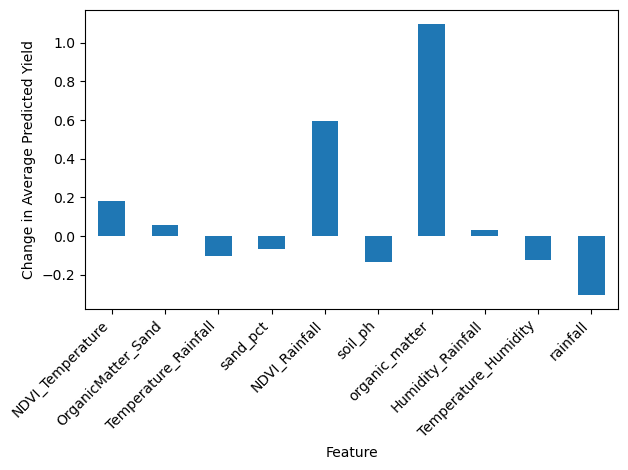

In [5]:
sensitivity.plot(
    x="Feature", y="Prediction_Change",
    kind="bar", legend=False
)

plt.ylabel("Change in Average Predicted Yield")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig("stage21_outputs/sensitivity.png")
plt.show()

In [6]:
print(os.listdir("stage21_outputs"))

['model_comparison.csv', 'sensitivity.png', 'what_if_analysis.csv']
